In [3]:
from langgraph.graph import StateGraph,START,END
from langgraph.checkpoint.memory import InMemorySaver
from langchain_openai import ChatOpenAI
from langchain_core.prompts import PromptTemplate
from dotenv import load_dotenv
from typing import TypedDict
import time

In [ ]:
class FaultState(TypedDict):
    input:str
    step_1:str
    step_2:str
    step_3:str

In [5]:
def execute_step_1(state:FaultState):
    print("Step 1 Executed")
    return {'step_1':'complete'}

In [6]:
def execute_step_2(state:FaultState):
    print("Step 2 Executing.......")
    time.sleep(30)
    return {'step_2':'complete'}

In [7]:
def execute_step_3(state:FaultState):
    print("Step 3 Executed")
    return {'step_3':'complete'}

In [8]:
graph=StateGraph(FaultState)

In [9]:
graph.add_node('execute_step_1',execute_step_1)
graph.add_node('execute_step_2',execute_step_2)
graph.add_node('execute_step_3',execute_step_3)


graph.add_edge(START,'execute_step_1')
graph.add_edge('execute_step_1','execute_step_2')
graph.add_edge('execute_step_2','execute_step_3')
graph.add_edge('execute_step_3',END)

In [10]:
checkpointer=InMemorySaver()

In [11]:
workflow=graph.compile(checkpointer=checkpointer)

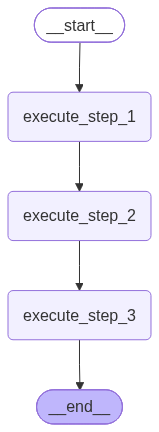

In [12]:
workflow

In [13]:
config={'configurable':{'thread_id':'1'}}

In [14]:
initial_state={'input':'start'}

In [19]:
final_state=workflow.invoke(initial_state,config=config)

Step 1 Executed
Step 2 Executing.......


KeyboardInterrupt: 

In [20]:
final_state

{'step_1': 'complete', 'step_2': 'complete', 'step_3': 'complete'}

In [21]:
list(workflow.get_state_history(config=config))

[StateSnapshot(values={'step_1': 'complete', 'step_2': 'complete', 'step_3': 'complete'}, next=('execute_step_2',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d3b59-cc39-6b74-8006-f3bf835e1af8'}}, metadata={'source': 'loop', 'step': 6, 'parents': {}}, created_at='2026-10-29T16:27:19.780206+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d3b59-cc33-6897-8005-d1c3286c1940'}}, tasks=(PregelTask(id='4700d5f3-a981-f08a-fc7d-f969db44dc51', name='execute_step_2', path=('__pregel_pull', 'execute_step_2'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'step_1': 'complete', 'step_2': 'complete', 'step_3': 'complete'}, next=('execute_step_1',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d3b59-cc33-6897-8005-d1c3286c1940'}}, metadata={'source': 'loop', 'step': 5, 'parents': {}}, created_at='2026-10-29T16:27:19.777681